# 🍄 Taller de Aprendizaje No Supervisado
## Parte 1 (SOLUCIÓN): Dataset de Setas (variables categóricas)

### La analogía que usaremos en todo el taller
Imaginen a una **recolectora de setas que acaba de llegar a un bosque que no conoce**. Tiene un cesto con 8.000 setas y **nadie le dijo cuáles son venenosas**.
Lo único que puede hacer es **mirarlas y juntar las que se parecen** (mismo olor, mismo color, misma forma). Eso es *clustering*.
Al final, una experta le dice la verdad (la etiqueta `class`) y comprobamos cuántas veces la recolectora acertó **sin haber recibido ayuda**.

| En la analogía | En el taller |
|---|---|
| El cesto de setas | El dataset (8.124 filas) |
| Mirar olor, color, forma | Las variables categóricas |
| Juntar las parecidas | Clustering (K-Means, GMM...) |
| La experta que revela la verdad | La etiqueta `class`, que **solo usamos para validar** |
| Una seta rarísima que no se parece a ninguna | Anomalía (Isolation Forest) |

### Qué resolvemos
Entender la diferencia entre **aprender con respuestas** y **aprender sin ellas**, y fijar qué haremos con este dataset.

### Por qué importa
Si esta diferencia no queda clara, no se entiende por qué la etiqueta `class` queda **guardada en un cajón** durante casi todo el taller.

### Para entenderlo
| | Supervisado | No supervisado |
|---|---|---|
| ¿Hay respuestas? | Sí, la experta nos corrige | No, solo tenemos el cesto |
| Pregunta | «¿Esta seta es venenosa?» | «¿Qué setas se parecen entre sí?» |
| Ejemplo en el taller | Random Forest | K-Means, PCA, DBSCAN |

Aquí el dataset **sí tiene etiqueta**, pero haremos como si no la tuviéramos. La usaremos al final, como el examen.

### Celda de importaciones
**Qué resolvemos:** traer todas las herramientas que usaremos en el taller de una sola vez.

**Por qué:** el enunciado dejaba solo las básicas y pedía importar el resto «a medida que las necesitemos». Aquí las dejamos todas juntas para no andar interrumpiendo la explicación.

| Librería | Para qué |
|---|---|
| `pandas`, `numpy` | Tablas y cálculos |
| `seaborn`, `matplotlib` | Gráficos |
| `sklearn.decomposition.PCA` | Reducir dimensiones (lineal) |
| `sklearn.manifold.TSNE` | Reducir dimensiones (no lineal) |
| `sklearn.cluster` | K-Means, Aglomerativo, DBSCAN |
| `sklearn.mixture.GaussianMixture` | GMM |
| `sklearn.metrics` | Evaluar los clusters |
| `scipy.cluster.hierarchy` | Dendrograma |
| `IsolationForest` | Anomalías |

**Para entenderlo:** `RANDOM_STATE = 42` es «la semilla»: hace que los resultados sean **iguales para todos** cada vez que ejecutemos. Sin ella, cada quien vería números distintos.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook, justo debajo de la celda que los crea.
import warnings
warnings.filterwarnings("ignore")  # oculta avisos (FutureWarning, etc.) para que la salida quede limpia en clase

# Tablas y cálculo numérico
import pandas as pd      # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np       # arrays y operaciones matemáticas rápidas
# Gráficos
import seaborn as sns            # gráficos estadísticos bonitos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos (títulos, ejes, plt.show())
# Preparación de datos y reducción de dimensiones
from sklearn.model_selection import train_test_split  # separa datos en entrenamiento y examen
from sklearn.decomposition import PCA                 # reducción de dimensiones lineal
# Algoritmos de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.manifold import TSNE                     # reducción de dimensiones no lineal (solo para visualizar)
from sklearn.mixture import GaussianMixture          # GMM: clusters como "nubes" probabilísticas
# Modelos supervisado y de anomalías
from sklearn.ensemble import RandomForestClassifier, IsolationForest
# Métricas para evaluar los clusters (3 internas + 2 que usan la etiqueta: ARI y NMI)
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
# Para dibujar el dendrograma
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')  # estilo visual de todos los gráficos: fondo blanco con rejilla
RANDOM_STATE = 42                 # semilla: hace que el azar sea siempre el mismo y todos obtengan los mismos resultados

### Leer conjunto de datos y primer vistazo

**Qué resolvemos:** cargar el CSV y mirar las primeras filas.

**Por qué:** nunca se trabaja con datos que no se han visto. Es como abrir el cesto antes de decidir cómo ordenar.

**Para entenderlo:** cada fila es **una seta**. Cada columna es **una característica que se puede observar**. Fíjense que los valores son **letras** (`x`, `s`, `n`...). Cada letra es una abreviatura: `x` = forma convexa, `s` = superficie lisa, `n` = color marrón. No son números, y esto será un problema más adelante.

In [2]:
# Lee el archivo CSV y lo guarda en una tabla (DataFrame) llamada df.
# Cada fila es una seta; cada columna, una característica.
df = pd.read_csv('data/mushrooms.csv')
# head() muestra solo las 5 primeras filas, para echar un vistazo sin imprimir 8.000 filas.
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Exploración de datos

**Qué resolvemos:** saber el tamaño del dataset y qué tipo de datos tenemos.

**Por qué:** `describe()` y `info()` son el «chequeo médico» de cualquier dataset. Responden: ¿cuántas filas?, ¿qué tipos?, ¿hay algo raro?

**Para entenderlo:** en `describe()` de un dataset de texto aparecen cuatro cosas: `count` (cuántos datos), `unique` (cuántas categorías distintas), `top` (la más común) y `freq` (cuántas veces sale la más común). Miren la columna `unique`: **ninguna pasa de 12 categorías**, así que son variables simples.

In [3]:
# df.shape devuelve (número de filas, número de columnas).
print("Filas y columnas:", df.shape)
# describe() resume cada columna. Con texto devuelve: count (datos), unique (categorías distintas),
# top (la categoría más común) y freq (cuántas veces aparece la más común).
df.describe()

Filas y columnas: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


**Qué resolvemos:** ver el tipo de dato de cada columna.

**Para entenderlo:** todo es `object`, que es la forma de pandas de decir «texto». Esto confirma que **no hay ni un solo número**: es lo que el enunciado llama «todas categóricas». Con datos así no podemos hacer un *scatterplot* directo (¿qué eje sería «la forma del sombrero»?).

In [4]:
# info() lista cada columna con su tipo de dato y cuántos valores no nulos tiene.
# Aquí todo es texto (object/str): confirma que no hay ninguna variable numérica.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

#### Calcular el número de nulos de cada feature

**Qué resolvemos:** comprobar si hay datos que faltan.

**Por qué:** muchos algoritmos fallan o dan resultados malos con valores vacíos.

**Para entenderlo:** `isnull()` marca con `True` cada casilla vacía y `sum()` las cuenta. **Todo da cero.** Pregúntense: *«¿Entonces no hay problemas con datos faltantes?»* La respuesta es: **todavía no lo sabemos**. Eso lo descubrimos en el siguiente paso.

In [5]:
# isnull() devuelve True en cada casilla vacía (NaN); sum() cuenta los True por columna.
# Todo da 0, pero eso NO descarta nulos disfrazados (como el '?' que veremos enseguida).
df.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

#### Buscar valores extraños. Para ello, ver los valores únicos en cada feature

**Qué resolvemos:** crear una tabla con, para cada variable, **cuáles son sus valores distintos** (`n_values`) y cuántos son (`n_unicos`).

**Por qué:** es un truco muy potente para detectar problemas escondidos. Una variable con **1 sola categoría** no sirve para nada. Y si entre los valores aparece algo raro (como un `'?'`), se ve a simple vista.

**Para entenderlo:** `df[a].unique()` devuelve los valores distintos de la columna `a`. Lo hacemos para todas las columnas con una lista por comprensión y lo metemos en un DataFrame. Fíjense en dos filas: `veil-type` tiene un solo valor (`['p']`) y `stalk-root` incluye el **`'?'`** entre sus letras. Ahí está el nulo encubierto.


In [6]:
columns = df.columns                                     # lista con los nombres de todas las columnas
n_values = [df[a].unique() for a in df.columns]          # para cada columna, sus valores distintos (unique)
                                                         # (es una "lista por comprensión": un bucle for en una línea)
counts = pd.DataFrame()                                  # tabla vacía donde iremos añadiendo columnas
counts['features'] = columns                             # 1a columna: el nombre de la variable
counts['n_values'] = n_values                            # 2a columna: los valores distintos que tiene (aquí se ve el '?')
counts['n_unique'] = [len(v) for v in n_values]          # 3a columna: cuántos valores distintos son (len = longitud de la lista)
counts                                                   # mostramos la tabla: busquen 'veil-type' (1 valor) y 'stalk-root' (con '?')

,features,n_values,n_unique
0,class,"[p, e]",2
1,cap-shape,"[x, b, s, f, k, c]",6
2,cap-surface,"[s, y, f, g]",4
3,cap-color,"[n, y, w, g, e, p, b, u, c, r]",10
4,bruises,"[t, f]",2
5,odor,"[p, a, l, n, f, c, y, s, m]",9
6,gill-attachment,"[f, a]",2
7,gill-spacing,"[c, w]",2
8,gill-size,"[n, b]",2
9,gill-color,"[k, n, g, p, w, h, u, e, b, r, y, o]",12


#### Tratar aquellos valores que entendamos que sean nulos

**Qué resolvemos:** descubrir y arreglar el **nulo encubierto** de `stalk-root`.

**Por qué:** esta es **la lección más importante del bloque**. Los nulos no siempre se llaman `NaN`. Aquí quien creó el dataset escribió `'?'` para decir «no sé». Pandas no sabe que eso significa «vacío», así que `isnull()` dio cero.

**Para entenderlo:** es como cuando alguien rellena un formulario y en «teléfono» pone «ninguno». El campo **no está vacío**, pero la información **sí falta**. Hay 3 opciones:

| Opción | Qué hace | Cuándo conviene |
|---|---|---|
| Borrar la fila | Pierdes datos | Si hay muy pocos nulos |
| Imputar con la moda | Rellena con el valor más común | Si hay bastantes y la variable es categórica |
| Dejar `'?'` como categoría | Trata «desconocido» como un valor más | Si «no saber» ya es información |

Aquí hay **2.480 setas con `'?'`** (casi el 30%), así que borrar sería perder demasiado. Imputamos con la **moda** (el valor más frecuente, **sin contar el `'?'`**).

**Error típico:** calcular la moda incluyendo el `'?'`. Si `'?'` fuera el más común, nos rellenaría con `'?'` y no habríamos arreglado nada. Por eso primero filtramos.

In [7]:
# (df['stalk-root'] == '?') da True/False por fila; sum() cuenta los True, o sea, cuántas setas tienen '?'.
print("Setas con '?' en stalk-root:", (df['stalk-root'] == '?').sum())

# Moda calculada SOLO con los valores conocidos
# df.loc[condición, columna] filtra las filas que cumplen la condición (!= '?') y se queda con esa columna.
# mode() devuelve los valores más frecuentes; [0] toma el primero.
mode_value = df.loc[df['stalk-root'] != '?', 'stalk-root'].mode()[0]
print("Moda de stalk-root:", mode_value)

# replace('?', mode_value) cambia cada '?' por la moda y guardamos el resultado en la misma columna.
df['stalk-root'] = df['stalk-root'].replace('?', mode_value)
# Comprobación: ahora debe dar 0.
print("Quedan '?':", (df['stalk-root'] == '?').sum())

Setas con '?' en stalk-root: 2480
Moda de stalk-root: b
Quedan '?': 0


#### ¿Todas las features aportan información? Si alguna no aporta, eliminadla

**Qué resolvemos:** quitar las columnas que valen lo mismo en todas las filas.

**Por qué:** si **todas** las setas tienen el mismo `veil-type`, esa columna no ayuda a distinguir una seta de otra. Es ruido.

**Para entenderlo:** si preguntan a 100 personas «¿respira usted?» y todas dicen sí, esa pregunta no sirve para separar a nadie. Dejamos un código genérico (`nunique() == 1`) para que funcione aunque haya más de una columna así.

In [8]:
# Para cada columna c, nunique() cuenta sus valores distintos; si es 1, la columna es constante.
# El resultado es una lista con los nombres de esas columnas (aquí solo veil-type).
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Columnas constantes:", constant_cols)
# drop(columns=...) elimina esas columnas y devolvemos el resultado a df.
df = df.drop(columns=constant_cols)
df.shape   # una columna menos que antes

Columnas constantes: ['veil-type']


(8124, 22)

#### Separar entre variables predictoras y variable a predecir

**Qué resolvemos:** apartar la etiqueta `class` de las demás columnas.

**Por qué:** este es **el momento clave del taller**. Guardamos la etiqueta en `y` y **no la dejamos en `X`**. Si se quedara en `X`, el clustering «haría trampa» y el experimento no valdría nada.

**Para entenderlo:** la recolectora trabaja solo con `X`. La experta guarda `y` en un sobre cerrado.

Creamos además `y_bin`: la misma etiqueta pero en **0 y 1** (`1` = venenosa). Las métricas de comparación de clusters (ARI, NMI) funcionan con letras o con números, pero tener la versión numérica nos viene bien más adelante.

In [9]:
y = df['class']                      # 'e' / 'p'  (el sobre cerrado): la etiqueta que NO usará el clustering
y_bin = (y == 'p').astype(int)       # 1 = venenosa, 0 = comestible: (y == 'p') da True/False y astype(int) lo pasa a 1/0
X = df.drop(columns='class')         # lo que ve la recolectora: todas las columnas menos la etiqueta
print(y.value_counts())              # cuántas setas hay de cada clase (casi mitad y mitad: dataset equilibrado)

class
e    4208
p    3916
Name: count, dtype: int64


#### Codificar correctamente las variables categóricas a numéricas (One-Hot)

**Qué resolvemos:** convertir letras en números **sin inventar un orden que no existe**.

**Por qué:** los algoritmos hacen cuentas con distancias, y no se puede restar «convexa» menos «plana». Primera idea tentadora: poner `convexa=1, plana=2, campana=3`. **Es un error**: el algoritmo pensaría que «plana» está en medio de las otras dos y que «campana» está más lejos de «convexa».

**Para entenderlo:** One-Hot es como un **panel de interruptores**. En vez de una columna `cap-shape` con letras, creamos una columna por cada forma posible: `cap-shape_x`, `cap-shape_b`... y cada seta tiene un `1` en la que le corresponde y `0` en las demás.

| Seta | cap-shape (antes) | cap-shape_x | cap-shape_b | cap-shape_f |
|---|---|---|---|---|
| A | x | 1 | 0 | 0 |
| B | b | 0 | 1 | 0 |
| C | f | 0 | 0 | 1 |

Con `pd.get_dummies` es **una línea**. Veremos cómo pasamos de 21 columnas a **115**: por eso esto se llama «alta dimensionalidad».

Usamos `dtype=int` para tener 0 y 1 (si no, pandas pone `True/False`, que funciona pero se ve menos claro).

In [10]:
# get_dummies crea una columna 0/1 por cada categoría de cada variable (One-Hot).
# dtype=int fuerza que sea 0/1 en lugar de False/True.
X = pd.get_dummies(X, dtype=int)
print("Forma tras One-Hot:", X.shape)   # pasamos de 21 columnas de texto a 115 columnas numéricas
X.head()

Forma tras One-Hot: (8124, 115)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


#### Train / test split

**Qué resolvemos:** separar los datos en un grupo para aprender y otro para examinar.

**Por qué:** esto aplica **sobre todo al Random Forest** que viene luego. Si el modelo se examina con las mismas setas con las que estudió, siempre sacaría 100 y no sabríamos si aprendió o memorizó.

**Para entenderlo:** `test_size=0.33` = 33% para el examen, 67% para estudiar. Esta celda venía **ya hecha** en el enunciado para que todos tengan la misma partición.

In [11]:
# Separa 67% para entrenar y 33% para examinar (test_size=0.33).
# random_state=42 hace que la partición sea la misma para todos.
# Devuelve 4 objetos: X de train/test e y de train/test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)
print(X_train.shape, X_test.shape)

(5443, 115) (2681, 115)


## PCA

**Qué resolvemos:** pasar de **115 dimensiones a 2** para poder dibujar los datos.

**Por qué:** nuestros ojos solo ven 2 o 3 dimensiones. PCA busca **los ejes en los que las setas más se diferencian** entre sí. Esos ejes se llaman **componentes principales**. Se ordenan: el primero captura la mayor variación, el segundo la siguiente, etc.

**Para entenderlo:** imaginen que fotografían un edificio. Hay fotos desde las que se ve poco (desde arriba, solo un rectángulo) y fotos desde las que se ve **casi todo** (desde una esquina). PCA es **buscar el mejor ángulo de la foto**. Pierdes información (3D pasa a 2D) pero eliges el ángulo que pierde menos.

**Detalles importantes:**
- **`fit` solo con `X_train`**. El PCA aprende los ejes viendo únicamente el grupo de estudio.
- **No usamos la etiqueta para entrenar el PCA.** Solo la usamos después para **pintar los puntos de colores**. Esa es la diferencia entre «usar la etiqueta» y «usarla para colorear».
- Los dos ejes **no tienen nombre** (no son «olor» ni «color»): son mezclas de muchas variables.

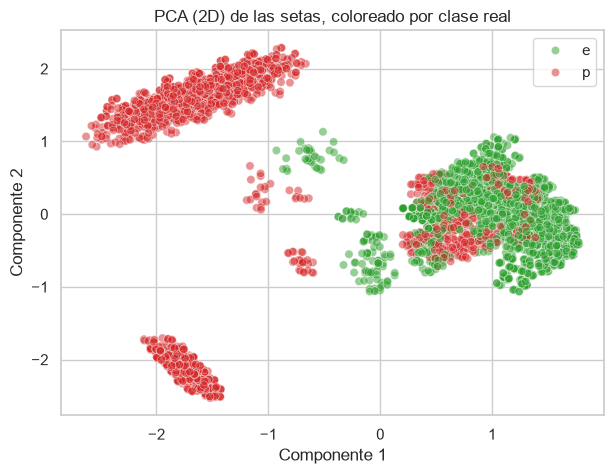

Varianza explicada por los 2 ejes: [0.169 0.127] = 0.296


In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)   # PCA que se quedará con las 2 mejores direcciones
pca.fit(X_train)                                       # aprende los ejes mirando SOLO los datos de entrenamiento (sin etiqueta)
Z = pca.transform(X_train)                             # proyecta cada seta a esas 2 coordenadas: Z[:, 0] y Z[:, 1]

plt.figure(figsize=(7, 5))                             # crea un lienzo de 7x5 pulgadas
# Scatter: eje x = componente 1, eje y = componente 2. hue colorea por clase real (solo para decorar, PCA no la vio).
# alpha=0.5 hace los puntos semitransparentes para ver dónde se acumulan; palette fija verde=comestible, rojo=venenosa.
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_train.values, alpha=0.5, palette={'e': 'tab:green', 'p': 'tab:red'})
plt.xlabel('Componente 1'); plt.ylabel('Componente 2')
plt.title('PCA (2D) de las setas, coloreado por clase real')
plt.show()
# explained_variance_ratio_ = fracción de información que guarda cada eje; la suma es lo que conservamos en total.
print("Varianza explicada por los 2 ejes:", pca.explained_variance_ratio_.round(3), "=", pca.explained_variance_ratio_.sum().round(3))

**Cómo leer el gráfico:** cada punto es una seta. **Verde = comestible, rojo = venenosa.** Se ven **tres zonas bien distintas**: dos «islas» **solo rojas** arriba a la izquierda y abajo a la izquierda (setas venenosas muy parecidas entre sí), unas islitas pequeñas sueltas, y una **gran nube a la derecha donde verde y rojo están mezclados**.

La línea que imprimimos nos dice que, con solo 2 ejes, guardamos **cerca del 30%** de la información total. El resto de la información está repartida en las otras 113 dimensiones. Eso explica por qué el centro se ve mezclado: **el dibujo en 2D es un resumen, no la realidad completa**.

> ¡Ojo con la trampa de pensamiento! PCA **no vio** los colores y aun así separó parcialmente. Eso significa que **la información de venenosa/comestible ya está escondida en cómo se parecen las setas**.

### Línea base supervisada: Random Forest

**Qué resolvemos:** averiguar **cuánta información útil hay realmente** en los datos, usando un modelo que **sí** ve la etiqueta.

**Por qué:** es un punto de referencia. Si un modelo supervisado, con toda la ayuda, solo llegara a 60%, sabríamos que el dataset es difícil y que no podemos esperar mucho del no supervisado. Si llega a casi 100%, sabemos que **la información está ahí**.

**Para entenderlo:** el Random Forest es **muchos árboles de decisión votando** (como pedirle opinión a 100 expertos y quedarse con la mayoría). Es el «estudiante con apuntes y respuestas». Después compararemos al «estudiante sin respuestas» (K-Means).

Tres pasos que pide el enunciado: **definir** (con `n_estimators`, el número de árboles), **entrenar** en train, y **medir la precisión** (`score`) en test.

In [13]:
# Random Forest = 100 árboles de decisión que votan. n_estimators es el número de árboles.
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)    # aprende CON etiqueta: relaciona las características con 'e'/'p'
# score() predice las setas de test y devuelve la proporción de aciertos (1.0 = 100%).
print("Precisión en test (115 features):", rf.score(X_test, y_test))

Precisión en test (115 features): 1.0


**Resultado:** 100% de precisión. Ojo: **este dataset es muy fácil** (el olor por sí solo ya delata casi todo). No esperen esta puntuación en problemas reales.

Veamos cuántas features tenemos actualmente:

In [14]:
# Número de filas y de columnas del conjunto de entrenamiento (115 columnas).
X_train.shape

(5443, 115)

### ¿Cuántas componentes necesita Random Forest?

**Qué resolvemos:** averiguar con **cuántas dimensiones** (de las 115) basta para mantener la precisión.

**Por qué:** reducir dimensiones es útil para **ir más rápido y quitar ruido**. Pero ¿cuánto podemos reducir sin perder calidad? Lo respondemos con un experimento: repetimos el mismo ejercicio con 1, 2, 3... componentes y miramos cuándo la precisión deja de mejorar.

**Para entenderlo:** es como **resumir un libro**. Con 1 frase pierdes casi todo, con 10 frases ya lo cuentas bien, con 100 páginas no ganas nada. Buscamos el punto donde **agregar más ya no vale la pena**.

El bucle hace tres cosas por cada `n`:
1. **Definir y ajustar PCA** con `n` componentes sobre `X_train`.
2. **Entrenar un Random Forest** sobre los datos ya reducidos.
3. **Guardar la precisión** en test.

**Detalle crucial:** el PCA se ajusta **solo con train**, y a test se le aplica `transform` (sin volver a ajustar). Si ajustáramos con todo, el examen «habría visto» los datos del test (se llama *data leakage*, fuga de información).

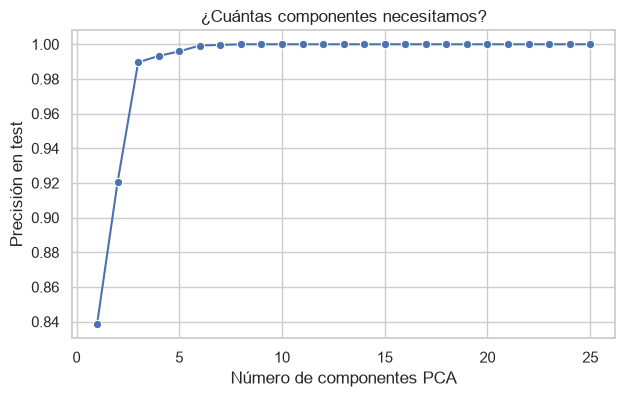

{1: 0.8385, 2: 0.9206, 3: 0.9896, 5: 0.9959, 10: 1.0}


In [15]:
n_features = range(1, 26)   # probaremos con 1, 2, 3 ... 25 componentes
scores = []                 # aquí guardaremos la precisión de cada prueba

for n in n_features:
    # 1) PCA con n componentes, ajustado SOLO con train (para no filtrar información del examen)
    p = PCA(n_components=n, random_state=RANDOM_STATE).fit(X_train)
    # 2) Un Random Forest nuevo, entrenado con los datos ya reducidos a n columnas
    rf_n = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
    rf_n.fit(p.transform(X_train), y_train)
    # 3) A test solo se le aplica transform (con los ejes aprendidos en train) y guardamos la precisión
    scores.append(rf_n.score(p.transform(X_test), y_test))

plt.figure(figsize=(7, 4))
sns.lineplot(x=list(n_features), y=scores, marker='o')     # curva: nº de componentes frente a precisión
plt.xlabel('Número de componentes PCA'); plt.ylabel('Precisión en test')
plt.title('¿Cuántas componentes necesitamos?')
plt.show()
# Diccionario con los valores de algunos puntos clave, para leerlos sin adivinar sobre el gráfico.
print({n: round(s, 4) for n, s in zip(n_features, scores) if n in (1, 2, 3, 5, 10)})

**Cómo leer el gráfico:**

| Componentes | Precisión aprox. |
|---|---|
| 1 | ~84% |
| 2 | ~92% |
| 3 | ~99% |
| 5 | ~99.6% |
| 10 | ~100% |

La curva **sube muy rápido y luego se aplana**. Con solo **10 de 115** ya recuperamos la precisión completa. Es decir, **el 91% de las columnas sobraba**. Esa cifra (10) es la que usaremos más adelante como «versión resumida» de los datos para el clustering.

## t-SNE: reducción **no lineal** para visualizar

**Qué resolvemos:** hacer **otro dibujo en 2D** de los datos, con un método distinto a PCA.

**Por qué:** PCA solo puede **girar y proyectar** (lineal), así que a veces mezcla grupos que sí son distintos. t-SNE hace otra cosa: intenta que **las setas parecidas queden juntas** en el dibujo, aunque tenga que estirar y doblar el espacio.

**Para entenderlo:**

| | PCA | t-SNE |
|---|---|---|
| Idea | Mejor «ángulo de foto» | Reunir a los vecinos |
| Es rápido | Sí | No (por eso usamos una muestra) |
| Los ejes significan algo | Un poco | **Nada** |
| Las distancias entre grupos | Se pueden leer | **No se pueden leer** |
| Sirve para | Reducir y entender | **Solo para visualizar** |

**Advertencia importante:** en t-SNE **el tamaño de un grupo y la distancia entre grupos no significan nada**. Solo vale mirar «quién está junto a quién». Tampoco se usa t-SNE para entrenar modelos.

Es lento, así que tomamos una **muestra de 2.000 setas**. `perplexity=30` es «a cuántos vecinos mira cada punto» (30 es el valor típico).

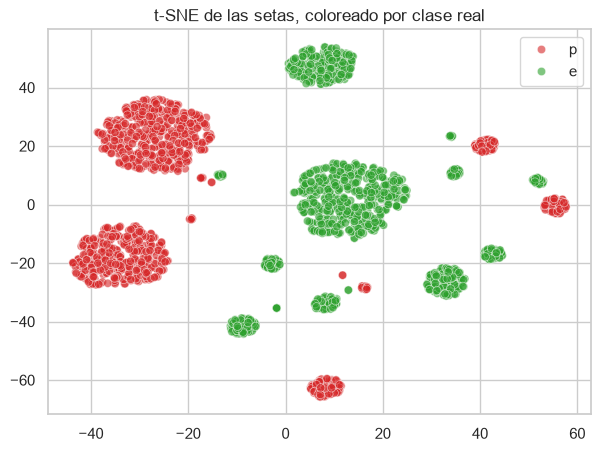

In [16]:
# t-SNE es lento, así que trabajamos con una muestra aleatoria de 2000 setas de train.
sample = X_train.sample(2000, random_state=RANDOM_STATE)
y_sample = y_train.loc[sample.index]     # sus etiquetas (solo para colorear): .loc busca por el mismo índice

# perplexity=30: cuántos vecinos mira cada punto. init='pca': arranca desde una proyección PCA (más estable).
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE)
emb = tsne.fit_transform(sample)         # calcula las 2 coordenadas de cada seta de la muestra

plt.figure(figsize=(7, 5))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_sample.values, alpha=0.6, palette={'e': 'tab:green', 'p': 'tab:red'})
plt.title('t-SNE de las setas, coloreado por clase real')
plt.show()

**Cómo leer el gráfico:** aquí sí aparecen **islas** (grupos separados) mucho más claras que en PCA, y la mayoría de islas son de un solo color. Esto nos dice que **hay estructura de grupos reales en los datos**, y que el clustering tiene sentido.

Pregúntense: *«¿Por qué el t-SNE se ve más limpio que el PCA?»* → porque permite **doblar el espacio**, mientras que PCA solo proyecta en línea recta.

---
## Clustering

**Qué resolvemos:** ahora sí, **juntar las setas por parecido, sin mirar la etiqueta**.

**Por qué trabajamos con `X_red`:** reducimos el dataset completo a **10 componentes PCA**. Lo decidimos en el bloque de PCA y Random Forest: 10 componentes conservan la información útil, y además:
- **limpian el ruido**,
- **aceleran** los algoritmos,
- hacen que la distancia euclídea tenga más sentido (en 115 dimensiones casi todo está «igual de lejos de todo»).

**Para entenderlo:** la recolectora trabaja con un **resumen de 10 notas** de cada seta, no con la ficha completa de 115 datos.

Esta vez ajustamos el PCA con **todo** `X` (no solo train). No hay problema, porque **no estamos evaluando un modelo con datos de test**: estamos agrupando, y no hay predicción que examinar.

In [ ]:
# Reducimos TODO el conjunto X (115 columnas) a 10 componentes y nos quedamos con el resultado (X_red).
# fit_transform = aprender los ejes y proyectar, en un solo paso.
X_red = PCA(n_components=10, random_state=RANDOM_STATE).fit_transform(X)
X_red.shape    # (8124, 10): 8124 setas, 10 columnas

(8124, 10)

### K-Means: ¿cuántos clusters? Codo + Silhouette

**Qué resolvemos:** decidir cuántos grupos (`k`) pedirle a K-Means.

**Por qué:** K-Means necesita que **nosotros** le digamos cuántos grupos. Si dijéramos mal el número, el resultado sería malo. Para elegirlo usamos dos «pistas»:

| Pista | Qué mide | Cómo se lee |
|---|---|---|
| **Inercia (codo)** | Qué tan lejos están las setas del centro de su grupo | Siempre baja al subir `k`. Buscamos el «**codo**»: donde deja de bajar tanto |
| **Silhouette** | Qué tan bien separados están los grupos | Va de -1 a 1. **Más alto = mejor** |

**Para entenderlo (cómo funciona K-Means):**
1. Se colocan `k` «imanes» (centroides) al azar.
2. Cada seta se va al imán más cercano.
3. Cada imán se mueve al centro de las setas que atrajo.
4. Se repite hasta que nada cambie.

**Advertencia honesta:** la inercia **siempre baja** al aumentar `k` (con un grupo por seta, valdría 0). Por eso **no sirve sola**. Y verán que el silhouette, en este caso, es mayor con `k` grande (~9). Eso **no significa** que haya 9 tipos de seta. Aquí entra **el conocimiento del problema**: sabemos que solo hay 2 clases (comestible/venenosa).

`n_init=10` = K-Means se ejecuta 10 veces con imanes iniciales distintos y se queda con la mejor, para evitar mala suerte con el azar.

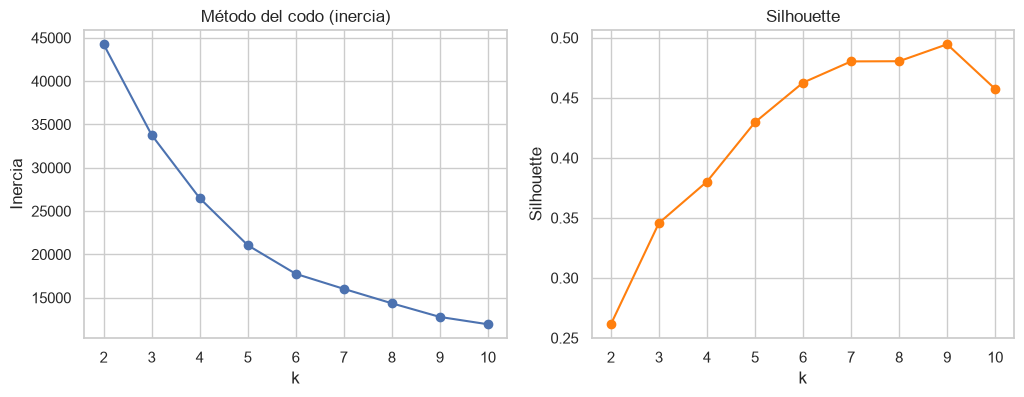

In [18]:
k_values = range(2, 11)                 # probaremos de 2 a 10 clusters
inertias, silhouettes = [], []          # dos listas vacías, una por métrica

for k in k_values:
    # n_init=10: K-Means se ejecuta 10 veces con "imanes" iniciales distintos y se queda con la mejor
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_red)
    inertias.append(km.inertia_)                              # suma de distancias de cada punto a su centroide
    silhouettes.append(silhouette_score(X_red, km.labels_))   # qué tan bien separados quedan los grupos (más alto = mejor)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))     # una figura con 2 gráficos lado a lado: ax[0] y ax[1]
ax[0].plot(list(k_values), inertias, marker='o'); ax[0].set_title('Método del codo (inercia)')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inercia')
ax[1].plot(list(k_values), silhouettes, marker='o', color='tab:orange'); ax[1].set_title('Silhouette')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette')
plt.show()

**Cómo leer los gráficos:**
- **Codo:** la curva baja de forma suave y **no hay un codo clarísimo** (esto pasa seguido con datos reales). Hay una caída fuerte entre `k=2` y `k=4` y luego se aplana poco a poco.
- **Silhouette:** sube y es mayor con `k` más grandes. Hay setas muy parecidas entre sí que forman **subgrupos** (por ejemplo, varios tipos de hongos comestibles distintos), y eso mejora la métrica.

> **Para quedarse con esto:** *las métricas ayudan, no deciden.* Y si el codo no se ve claro, no se inventa uno. Cuando sabemos algo del problema (aquí, que hay 2 clases), eso pesa más. Elegimos **`k=2`**.

### K-Means final y comparación con la etiqueta

**Qué resolvemos:** entrenar K-Means con `k=2` y, por fin, **abrir el sobre**: ¿coinciden los grupos con comestible/venenosa?

**Por qué:** es el momento de validar. Usamos dos métricas que comparan el agrupamiento con la etiqueta real:

| Métrica | Idea | 0 significa | 1 significa |
|---|---|---|---|
| **ARI** (Adjusted Rand Index) | ¿Las parejas de setas que quedaron juntas coinciden con las de la etiqueta? | Azar puro | Idéntico |
| **NMI** (Normalized Mutual Information) | ¿Cuánto me dice el cluster sobre la clase real? | Nada | Todo |

**Para entenderlo:** el cluster **no se llama «venenoso» ni «comestible»**, se llama `0` y `1` (y cuál es cuál es arbitrario). Por eso ARI y NMI **no comparan nombres, comparan quién quedó con quién**. Esa es su ventaja.

El `catplot` cuenta cuántas setas de cada clase real cayó en cada cluster. Si fuera perfecto, cada cluster tendría un solo color.

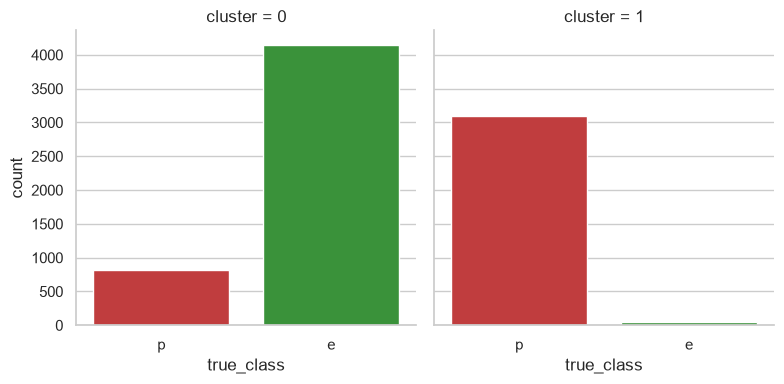

ARI: 0.617
NMI: 0.566


In [ ]:
# Entrenamos K-Means con k=2 (sabemos que hay 2 clases). NO se le pasa la etiqueta.
kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_red)
labels_km = kmeans.labels_     # el cluster (0 o 1) que K-Means asignó a cada seta

# Tabla auxiliar con el cluster y la clase real de cada seta, para poder contarlas juntas.
tmp = pd.DataFrame({'cluster': labels_km, 'true_class': y.values})
# catplot kind='count': una barra por cada clase real, un panel (col) por cada cluster.
# Si el clustering fuera perfecto, cada panel tendría una sola barra.
sns.catplot(data=tmp, x='true_class', col='cluster', kind='count', palette={'e': 'tab:green', 'p': 'tab:red'},
            hue='true_class', legend=False, height=4)
plt.show()

# ARI y NMI comparan los grupos de K-Means con la etiqueta real (0 = azar, 1 = idéntico).
print("ARI:", round(adjusted_rand_score(y_bin, labels_km), 3))
print("NMI:", round(normalized_mutual_info_score(y_bin, labels_km), 3))

**Resultado:** ARI ≈ **0.62** y NMI ≈ **0.57**. Un cluster tiene **mayoría de comestibles** y el otro **mayoría de venenosas**, pero **ambos están algo mezclados**. Sin ver ni una etiqueta, **K-Means recuperó buena parte de la estructura real**. Pero no es perfecto.

> **Para quedarse con esto:** el no supervisado no da «la respuesta», da **una pista muy buena**. Random Forest sacó 100% porque tenía las respuestas. K-Means sacó un ARI de ~0.6 sin ninguna.

### Comparativa de algoritmos de clustering

**Qué resolvemos:** poner a competir **K-Means, Aglomerativo, GMM y DBSCAN** con las mismas métricas y en la misma tabla.

**Por qué:** ningún algoritmo gana siempre. Una tabla permite comparar de un vistazo.

**Para entenderlo (una frase por algoritmo):**

| Algoritmo | En una frase | Necesita decirle `k` |
|---|---|---|
| **K-Means** | «Imanes» que atraen a los más cercanos | Sí |
| **Aglomerativo** | Une las setas más parecidas de a dos, y luego los grupos, hasta formar un árbol | Sí (al cortar el árbol) |
| **GMM** | Cada grupo es una «nube» probabilística; cada seta tiene una probabilidad de pertenecer a cada nube | Sí |
| **DBSCAN** | Un grupo es una zona **densa** de setas; lo que queda aislado es ruido | **No**, pero necesita `eps` y `min_samples` |

**Las cuatro métricas:**

| Métrica | ¿Usa etiqueta? | Mejor cuando es... |
|---|---|---|
| Silhouette | No (interna) | Más **alta** |
| Davies-Bouldin | No (interna) | Más **baja** |
| Calinski-Harabasz | No (interna) | Más **alta** |
| ARI | **Sí** (externa) | Más **alta** |

La función `evaluate` devuelve las 4 en un diccionario. Tiene un detalle: **DBSCAN etiqueta con `-1` los puntos que considera «ruido»**. Para calcular las métricas internas **excluimos el ruido** (si no, el ruido contaría como un cluster más).

Para DBSCAN usamos `eps=1.5` y `min_samples=10` (`eps` = radio de «vecindad», `min_samples` = cuántos vecinos hacen falta para llamarlo «zona densa»). Estos valores salieron de **probar varios** (lo veremos en el bloque de DBSCAN).

In [20]:
# Función que calcula todas las métricas de un clustering y las devuelve en un diccionario.
def evaluate(name, labels, X, y_ref=None):
    """Devuelve silhouette, Davies-Bouldin, Calinski-Harabasz y ARI (si hay etiqueta)."""
    labels = np.asarray(labels)               # nos aseguramos de que sea un array de numpy
    ok = labels != -1                         # DBSCAN usa -1 para el ruido; ok = True en los puntos que sí tienen cluster
    n_clusters = len(set(labels[ok]))         # set() quita repetidos: cuántos clusters distintos hay (sin contar ruido)
    row = {'algorithm': name, 'n_clusters': n_clusters, 'noise': int((~ok).sum())}   # ~ok = puntos de ruido
    if n_clusters >= 2:                       # las métricas internas necesitan al menos 2 clusters
        row['silhouette'] = silhouette_score(X[ok], labels[ok])             # más alto = mejor
        row['davies_bouldin'] = davies_bouldin_score(X[ok], labels[ok])     # más BAJO = mejor
        row['calinski_harabasz'] = calinski_harabasz_score(X[ok], labels[ok])  # más alto = mejor
    if y_ref is not None:                     # solo si tenemos etiqueta de referencia
        row['ARI'] = adjusted_rand_score(y_ref, labels)
    return row

# Los otros tres algoritmos. fit_predict = entrenar y devolver directamente el cluster de cada seta.
labels_agg = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(X_red)   # ward: une los grupos que menos dispersión añaden
labels_gmm = GaussianMixture(n_components=2, random_state=RANDOM_STATE).fit_predict(X_red)
labels_db  = DBSCAN(eps=1.5, min_samples=10).fit_predict(X_red)   # eps = radio de vecindad; min_samples = vecinos para ser zona densa

# Una fila por algoritmo -> DataFrame; set_index pone el nombre del algoritmo como índice; round(3) redondea.
results = pd.DataFrame([
    evaluate('KMeans (k=2)',      labels_km,  X_red, y_bin),
    evaluate('Aglomerativo (k=2)', labels_agg, X_red, y_bin),
    evaluate('GMM (k=2)',          labels_gmm, X_red, y_bin),
    evaluate('DBSCAN (eps=1.5)',   labels_db,  X_red, y_bin),
]).set_index('algorithm').round(3)
results

,n_clusters,noise,silhouette,davies_bouldin,calinski_harabasz,ARI
algorithm,,,,,,
KMeans (k=2),2,0,0.261,1.693,2564.691,0.617
Aglomerativo (k=2),2,0,0.259,1.696,2503.625,0.609
GMM (k=2),2,0,0.258,1.701,2500.017,0.599
DBSCAN (eps=1.5),6,0,0.358,1.071,2304.340,0.374


**Cómo leer la tabla:**
- **K-Means, Aglomerativo y GMM** se parecen mucho: ARI ≈ 0.60 a 0.62. Los tres encuentran la misma estructura.
- **DBSCAN** sale **mucho peor en ARI** (~0.37) y, además, encontró **6 clusters en vez de 2**. Necesita que su `eps` esté bien afinado y que la distancia sea la adecuada (siguiente bloque).
- **Sorpresa útil:** DBSCAN tiene el **silhouette más alto (0.36)** y a la vez el **peor ARI**. Sus 6 clusters son compactos y bien separados (por eso puntúa bien por dentro) pero **no coinciden con comestible/venenosa**. Moraleja: una métrica interna alta no garantiza que los grupos sean los que nos interesan, y **no se compara silhouette entre algoritmos con distinto número de clusters**.

### Dendrograma (clustering jerárquico)

**Qué resolvemos:** visualizar **cómo el algoritmo aglomerativo va uniendo** las setas en un árbol.

**Por qué:** es la forma de «ver» el clustering jerárquico. La **altura** a la que se unen dos ramas indica **qué tan distintos eran**. Un salto grande de altura significa «estas dos ramas eran muy diferentes, no deberían haberse unido».

**Para entenderlo:** es un **árbol genealógico al revés**. Abajo están las setas individuales. Cada vez que dos se parecen lo suficiente, se juntan en una rama. Para obtener `k` grupos, **cortan el árbol con una línea horizontal**: cuantas ramas atraviesan esa línea, tantos grupos.

El método `ward` une siempre los grupos cuya fusión **aumenta menos la dispersión interna**.

Usamos una **muestra de 150 setas**: con 8.000 el árbol sería una mancha ilegible.

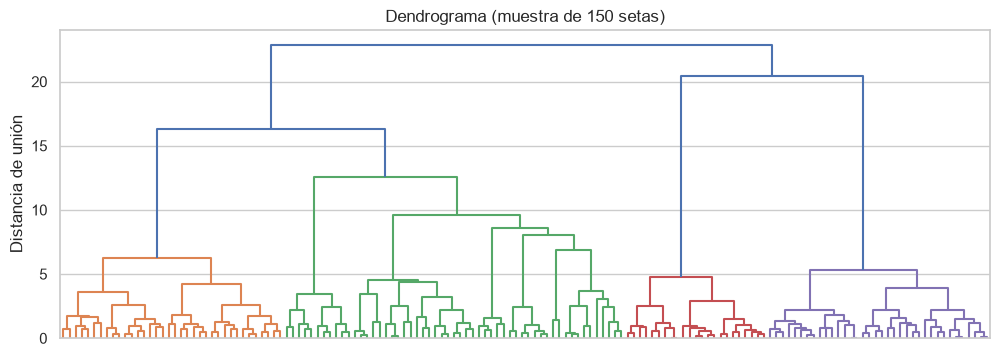

In [21]:
# Muestra aleatoria de 150 filas (índices sin repetir): con 8000 hojas el árbol sería ilegible.
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_red), 150, replace=False)
# linkage construye el árbol de uniones; 'ward' = une los grupos cuya fusión aumenta menos la dispersión.
Z_link = linkage(X_red[idx], method='ward')

plt.figure(figsize=(12, 4))
dendrogram(Z_link, no_labels=True)     # dibuja el árbol; no_labels=True oculta los números de cada hoja
plt.title('Dendrograma (muestra de 150 setas)')
plt.ylabel('Distancia de unión')       # cuanto más alta la unión, más distintos eran los grupos
plt.show()

**Cómo leer el gráfico:** fíjense que **arriba hay dos ramas grandes** (cortando ahí salen **2 grupos**, nuestro `k=2`) y que cada una se parte a su vez en subramas (los **4 colores** que dibuja scipy). Es la misma historia de antes: hay **2 grandes familias con subgrupos dentro**, por eso el silhouette premiaba `k` más grande. Es otra forma de decidir `k` que complementa al codo.

### DBSCAN: la **métrica de distancia importa**

**Qué resolvemos:** comprobar que **cambiar la forma de medir «qué tan parecidas son dos setas»** puede cambiar el resultado.

**Por qué:** DBSCAN decide por **distancias** quién es vecino de quién, así que depende totalmente de cómo se miden.

| Distancia | Cómo mide | Dónde aplicarla |
|---|---|---|
| **Euclídea** | Línea recta entre dos puntos | Datos numéricos continuos (nuestro `X_red` de PCA) |
| **Jaccard** | «De las características que tiene alguna de las dos setas, ¿cuántas comparten?» | Datos **binarios** (nuestro One-Hot) |

**Para entenderlo (ejemplo de Jaccard):** dos setas con 10 características «encendidas» cada una, de las cuales comparten 8. Jaccard dice: «comparten 8 de 12 en total, o sea se parecen un 67%». Jaccard **ignora los ceros compartidos**: que dos setas *no* tengan una característica no las hace más parecidas. En One-Hot hay muchísimos ceros, así que esto es clave.

**Detalle de honestidad:** DBSCAN es muy **sensible a `eps`**. Por eso barremos varios valores en vez de elegir uno al azar. Mostramos los resultados para que vean que **no hay un `eps` mágico**: hay que probar.

Para Jaccard usamos la matriz One-Hot **completa y convertida a booleano** (`astype(bool)`), no la versión PCA.

In [22]:
rows = []    # aquí iremos guardando una fila de resultados por cada prueba

# 1) DBSCAN con distancia euclídea sobre los datos reducidos con PCA, probando varios eps.
for eps in [0.5, 1.0, 1.5, 2.0]:
    l = DBSCAN(eps=eps, min_samples=10, metric='euclidean').fit_predict(X_red)
    rows.append({'distance': 'euclídea (PCA)', 'eps': eps,
                 'n_clusters': len(set(l) - {-1}),                  # clusters encontrados (restando la etiqueta -1 de ruido)
                 'noise': int((l == -1).sum()),                     # cuántos puntos quedaron como ruido
                 'ARI': round(adjusted_rand_score(y_bin, l), 3)})   # qué tanto coincide con la etiqueta real

# 2) DBSCAN con distancia de Jaccard sobre el One-Hot original, convertido a booleano (Jaccard lo necesita así).
X_bool = X.values.astype(bool)
for eps in [0.2, 0.3, 0.4, 0.5]:
    l = DBSCAN(eps=eps, min_samples=10, metric='jaccard').fit_predict(X_bool)
    rows.append({'distance': 'Jaccard (One-Hot)', 'eps': eps,
                 'n_clusters': len(set(l) - {-1}),
                 'noise': int((l == -1).sum()),
                 'ARI': round(adjusted_rand_score(y_bin, l), 3)})

pd.DataFrame(rows)     # convertimos la lista de diccionarios en una tabla para compararlas

,distance,eps,n_clusters,noise,ARI
0,euclídea (PCA),0.5,130,690,0.021
1,euclídea (PCA),1.0,36,24,0.175
2,euclídea (PCA),1.5,6,0,0.374
3,euclídea (PCA),2.0,4,0,0.080
4,Jaccard (One-Hot),0.2,19,16,0.275
5,Jaccard (One-Hot),0.3,14,16,0.262
6,Jaccard (One-Hot),0.4,5,8,0.443
7,Jaccard (One-Hot),0.5,3,5,-0.001


**Cómo leer la tabla:**
- **Euclídea:** el mejor ARI es ~0.37 (con `eps=1.5`).
- **Jaccard:** el mejor ARI es ~0.44 (con `eps=0.4`). **Mejora, pero no es una diferencia espectacular.**
- Con `eps` mal elegido, **ambas** fallan: ARI cerca de 0, o 130 clusters diminutos.

> **Lección honesta:** la distancia correcta ayuda, pero **la elección de `eps` pesa casi tanto**. Y en ambos casos DBSCAN queda por debajo de K-Means en estos datos. **No hay un algoritmo que gane siempre: depende del tipo de datos y de los parámetros.**

El *porqué*: las setas forman grupos **de densidad parecida** y bastante entremezclados, y DBSCAN funciona mejor cuando los grupos están **claramente separados por zonas vacías**.

### Visualización final: clusters vs etiqueta real

**Qué resolvemos:** poner **lado a lado** lo que encontró K-Means y lo que decía la etiqueta real.

**Por qué:** es el «momento de la verdad» visual. Si los dos dibujos se parecen, el clustering funcionó.

**Para entenderlo:** a la izquierda, **lo que la recolectora agrupó sin ayuda**. A la derecha, **lo que la experta sabía**. Los colores pueden estar cambiados (el cluster 0 no tiene por qué ser «comestible»): **lo que importa es la forma de las manchas**, no el color.

Entrenamos un PCA(2) sobre `X` completo, solo para pintar.

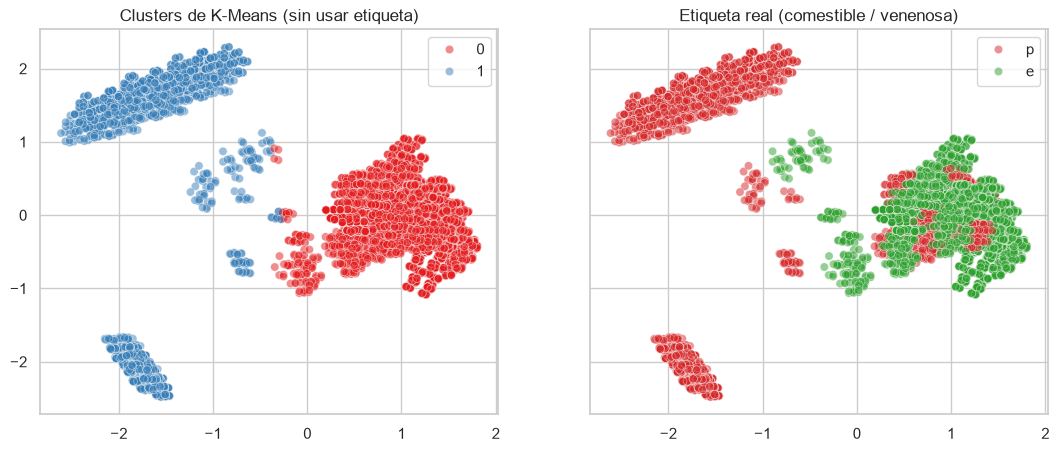

In [23]:
# PCA a 2 componentes sobre X completo, solo para tener coordenadas con las que dibujar.
P2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

# Dos gráficos lado a lado que comparten ejes (sharex/sharey) para poder compararlos directamente.
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
# Izquierda: mismos puntos, coloreados por el cluster que encontró K-Means.
sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=labels_km, palette='Set1', alpha=0.5, ax=ax[0])
ax[0].set_title('Clusters de K-Means (sin usar etiqueta)')
# Derecha: mismos puntos, coloreados por la etiqueta real.
sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=y.values, palette={'e': 'tab:green', 'p': 'tab:red'}, alpha=0.5, ax=ax[1])
ax[1].set_title('Etiqueta real (comestible / venenosa)')
plt.show()

Es bastante parecido, ¿no? No es tan bueno como Random Forest (que usa etiquetas), pero K-Means ha identificado bastante bien la estructura **sin usarlas**. Si no tuviéramos etiquetas, esta aproximación nos ayudaría mucho a clasificar los tipos de hongos.

> **Aplicación real:** esta idea sirve cuando **etiquetar es caro** (por ejemplo, que un experto revise miles de casos). Se agrupa primero, y el experto solo revisa **un representante por grupo**.

---
## Detección de anomalías (Isolation Forest)

**Qué resolvemos:** encontrar las setas **más raras**, las que no se parecen a casi ninguna.

**Por qué:** es otra tarea del aprendizaje no supervisado: en vez de agrupar, **detectar lo atípico**. Sirve para fraude, fallas en máquinas, errores de datos...

**Para entenderlo:** imaginen un juego de **«¿Quién es?»** donde hay que aislar a una persona haciendo preguntas de sí/no al azar. A una persona **normal** (con muchas parecidas) hay que hacerle muchas preguntas para dejarla sola. A una persona **rara** (única) la aislas con **muy pocas preguntas**. Isolation Forest hace eso con cortes aleatorios: **los puntos que se aíslan rápido son las anomalías**.

**Parámetros y resultado:**
- `contamination=0.05` = «asumo que ~5% de las setas son atípicas». **Es una decisión nuestra**, no algo que el algoritmo descubra.
- `predict` devuelve **`-1` para anomalía y `1` para normal**.
- Las pintamos sobre la proyección PCA para ver **dónde** están.

**Advertencia:** una anomalía **no es lo mismo que «venenosa»**. Es simplemente «rara». La última línea de la celda lo comprueba: de las ~400 anomalías, **unas 320 son comestibles y solo ~80 venenosas**. Son raras, no peligrosas.

Anomalías detectadas: 407 de 8124


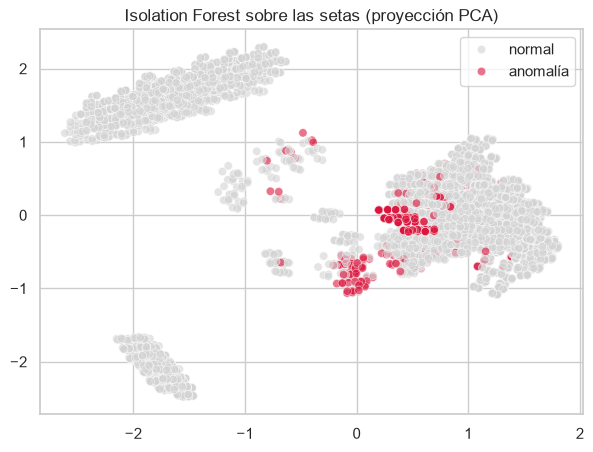


Clase real de las anomalías (extra: ¿son más venenosas?):
class
e    324
p     83
Name: count, dtype: int64


In [24]:
# contamination=0.05: asumimos que ~5% de las setas son atípicas (decisión nuestra, no del algoritmo).
iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE).fit(X_red)
pred = iso.predict(X_red)            # -1 = anomalía, 1 = normal
print("Anomalías detectadas:", (pred == -1).sum(), "de", len(pred))

plt.figure(figsize=(7, 5))
# np.where(condición, a, b): pone 'anomalía' donde pred == -1 y 'normal' en el resto, para colorear.
sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=np.where(pred == -1, 'anomalía', 'normal'),
                palette={'normal': 'lightgrey', 'anomalía': 'crimson'}, alpha=0.6)
plt.title('Isolation Forest sobre las setas (proyección PCA)')
plt.show()

# Extra: usamos la etiqueta real para comprobar si las anomalías son más venenosas (spoiler: no).
print("\nClase real de las anomalías (extra: ¿son más venenosas?):")
print(y[pred == -1].value_counts())

## Para ir más allá (opcional)

- **UMAP** (`pip install umap-learn`): alternativa a t-SNE, más rápida y preserva mejor la estructura global.
- **HDBSCAN** (`pip install hdbscan`): DBSCAN jerárquico que no necesita fijar `eps` (resuelve justo el problema que vimos).
- **Reglas de asociación** (`mlxtend`, Apriori/FP-Growth): muy naturales aquí por ser datos categóricos; permiten descubrir reglas tipo «si olor = X entonces venenosa».

## Conclusiones

- PCA y t-SNE nos dejaron *ver* un dataset de más de 100 dimensiones.
- K-Means, GMM y Aglomerativo recuperan la estructura comestible/venenosa con ARI ~0.6 **sin usar la etiqueta**.
- DBSCAN nos enseñó que **la métrica de distancia importa** con datos categóricos (y que `eps` también).
- Isolation Forest localiza las setas más atípicas.
- El no supervisado no da una respuesta «perfecta», pero descubre estructura muy útil cuando no tenemos etiquetas.